# Dynamic Model in Levels

**Fine-tuned EmbeddingGemma 2 version** of `main/code/04_evaluation.ipynb`: the DoubleMLDeep product embeddings are replaced by [EmbeddingGemma 2](https://huggingface.co/google/embeddinggemma-2) embeddings fine-tuned with LoRA and the loss of the DoubleMLDeep model on the training sample (`finetune_gemma.py`, `00_finetune_gemma_colab.ipynb`; text + image, Matryoshka 256 dimensions). Datasets are read from `Gemma-tuned/data`, raw data from `main/data`, outputs are written to `Gemma-tuned/outputs`.

Apart from the parameters below, the check of the estimation sample (cell writing `main_*_keys.csv` in `main/code`), the sensitivity scenarios at the residual shares of the main analysis and the export of the key results at the end, the notebook is identical to `main/code/04_evaluation.ipynb`.

In [1]:
# Parameters (default: fine-tuned EmbeddingGemma 2 text + image embeddings, 256 dimensions)
data_dir = "../data"  # "../../main/data": DoubleMLDeep embeddings as in main/code/04_evaluation.ipynb
txt_only = True  # True: text-only embeddings (datasets from 01_2_create_dataset_txt.ipynb)
emb_dim = 256  # Matryoshka dimension of the fine-tuned EmbeddingGemma 2 embeddings: 256 | 768 (text + image only)
output_dir = '../outputs/04_evaluation_comparison/tuned_txt_dim256'

In [2]:
import os
import datasets
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score

import doubleml as dml

from utils.utils_data2 import (
    get_cis,
    generate_basis,
    generate_interactions,
)

from utils.utils_models import (
    iv_model,
    lin_model,
    lin_model_cate,
    summarize_lin_model,
    summarize_dml,
    chi2_test,
    predict_cate,
)
import warnings
warnings.filterwarnings("ignore")

# Get a colorblind-friendly palette
palette = sns.color_palette("colorblind")

confidence_level = 0.9
ci_level_name, ci_names = get_cis(confidence_level)

Path(output_dir).mkdir(parents=True, exist_ok=True)

/tmp/claude-0/-home-user-demand-analysis-repro/8871aba3-e06d-5440-87b8-bf4072e29cf1/scratchpad/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Confidence Level: 90.0%


In [3]:
include_embeddings = True
dataframe_name = f"dataset_txt_only_{txt_only}_embeddings_{include_embeddings}"
if emb_dim != 256:
    dataframe_name += f"_dim{emb_dim}"
df_full_train = pd.read_csv(f"{data_dir}/{dataframe_name}_train.zip")
df_full_val = pd.read_csv(f"{data_dir}/{dataframe_name}_val.zip")

columns_to_drop = [
    "Q_t-2",
    "P_bb_t-2",
    "REVIEW_COUNT_t-2",
    "RATING_t-2",
    "pred_ml_l_lag_1",
    "pred_ml_m_lag_1",
]


df_full_train = df_full_train.drop(columns=columns_to_drop)
df_full_val = df_full_val.drop(columns=columns_to_drop)

df_full_train = df_full_train.dropna()
df_full_val = df_full_val.dropna()

dummy_subcat_names = [
    category for category in df_full_val["subcat_aggregated"].unique()
]
all_time_steps = sorted([str(date) for date in df_full_val["date"].unique()])

print(f"Dummy subcat names: {dummy_subcat_names}")
print(f"All time steps: {all_time_steps}")
df_full_val.columns

Dummy subcat names: ['Residual', 'Cars & Race Cars', 'Trains & Trams', 'Train Sets', 'Trucks', 'Tractors', 'Race Tracks', 'Airplanes', 'Motor Vehicles', 'Vehicle Playsets', 'Skateboards']
All time steps: ['2023-02-27', '2023-03-27', '2023-04-24', '2023-05-22', '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11', '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01', '2024-01-29']


Index(['ASIN', 'date', 'index', 'Q_t', 'PRICE', 'P_bb_t', 'text', 'window',
       'REVIEW_COUNT', 'RATING',
       ...
       'REVIEW_COUNT_t-1', 'RATING_t-1', 'Delta_Q_t', 'Delta_P_bb_t',
       'pred_ml_l', 'pred_ml_m', 'pred_ml_l_diff', 'pred_ml_m_diff',
       'pred_ml_l_diff_lag_1', 'pred_ml_m_diff_lag_1'],
      dtype='object', length=342)

In [4]:
print(dataframe_name)

dataset_txt_only_True_embeddings_True


In [5]:
print(df_full_val.shape)
print(df_full_train.shape)

(38041, 342)
(38146, 342)


In [6]:
# same estimation sample as in the main analysis (keys written by main/code/04_evaluation.ipynb)
assert df_full_val[["ASIN", "date"]].reset_index(drop=True).equals(pd.read_csv("../../main/code/main_val_keys.csv"))
assert df_full_train[["ASIN", "date"]].reset_index(drop=True).equals(pd.read_csv("../../main/code/main_train_keys.csv"))

In [7]:
df_full_val.isna().sum()

ASIN                    0
date                    0
index                   0
Q_t                     0
PRICE                   0
                       ..
pred_ml_m               0
pred_ml_l_diff          0
pred_ml_m_diff          0
pred_ml_l_diff_lag_1    0
pred_ml_m_diff_lag_1    0
Length: 342, dtype: int64

In [8]:
df_full_train["date"].unique()

array(['2023-02-27', '2023-03-27', '2023-04-24', '2023-05-22',
       '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11',
       '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01',
       '2024-01-29'], dtype=object)

In [9]:
df_full_val["date"].unique()

array(['2023-02-27', '2023-03-27', '2023-04-24', '2023-05-22',
       '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11',
       '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01',
       '2024-01-29'], dtype=object)

In [10]:
df_full_train["ASIN"].nunique()

3717

In [11]:
df_full_val["ASIN"].nunique()

3708

In [12]:
from datetime import datetime

date_objects = [datetime.strptime(date, "%Y-%m-%d") for date in all_time_steps]

# Calculate the difference in days between consecutive dates
date_differences = [
    (date_objects[i + 1] - date_objects[i]).days for i in range(len(date_objects) - 1)
]

# Print the differences
print(date_differences)

[28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28]


## Variable Names

In [13]:
n_lags = 1

outcome = ["Q_t"]
base_treatment = ["P_bb_t"]
lag_1_vars = ["Q_t-1", "P_bb_t-1"]

dummy_time_steps = all_time_steps[n_lags:]

all_dummy_controls = (
    dummy_subcat_names
    + dummy_time_steps
    + [
        "Lightning Deals: Upcoming Deal",
        "Buy Box: Is FBA",
    ]
)
dummy_baselines = [dummy_time_steps[0], "Residual"]
dummy_time_steps_wo_baseline = [t for t in dummy_time_steps if t not in dummy_baselines]
dummy_controls = [t for t in all_dummy_controls if t not in dummy_baselines]

cont_controls = [
    "RATING_t-1",
    "REVIEW_COUNT_t-1",
    "New Offer Count: Current",
    "Count of retrieved live offers: New, FBA",
    "Count of retrieved live offers: New, FBM",
]

add_controls_to_scale = [
    "RATING",
    "REVIEW_COUNT",
]

controls_pca = ["pca_0", "pca_1", "pca_2", "pca_3", "pca_4"]
controls_similarities = [
    "similarity_cluster_0",
    "similarity_cluster_1",
    "similarity_cluster_2",
    "similarity_cluster_3",
    "similarity_cluster_4",
]

embeddings = [f"emb_{i}" for i in range(emb_dim)]
assert set(embeddings) == {c for c in df_full_val.columns if c.startswith("emb_")}

controls_to_scale = cont_controls + add_controls_to_scale

additional_controls = cont_controls + dummy_controls

## Interactions & CATE Basis

In [14]:
basis_vars = controls_similarities + lag_1_vars
df_basis, column_transformer, column_dict = generate_basis(
    df=df_full_val,
    cols_without_scaling=controls_similarities,
    cols_to_scale=lag_1_vars,
    degree=1,
)
df_basis.head()

,intercept,Q_t-1,P_bb_t-1,similarity_cluster_0,similarity_cluster_1,similarity_cluster_2,similarity_cluster_3,similarity_cluster_4
0,1.0,0.305280,0.463601,-0.102049,0.058408,0.057394,0.069051,-0.042671
1,1.0,0.272505,0.653600,-0.102049,0.058408,0.057394,0.069051,-0.042671
2,1.0,0.036240,0.687961,-0.102049,0.058408,0.057394,0.069051,-0.042671
3,1.0,0.025283,0.636881,-0.102049,0.058408,0.057394,0.069051,-0.042671
4,1.0,-0.051370,0.556816,-0.102049,0.058408,0.057394,0.069051,-0.042671


In [15]:
df_interact_val, interaction_vars = generate_interactions(
    df=df_full_val, df_basis=df_basis, cols_to_interact=["Q_t-1", "P_bb_t-1"]
)

print(f"Interactions: {interaction_vars}")
df_interact_val.columns

Interactions: ['interaction_Q_t-1_intercept', 'interaction_Q_t-1_Q_t-1', 'interaction_Q_t-1_P_bb_t-1', 'interaction_Q_t-1_similarity_cluster_0', 'interaction_Q_t-1_similarity_cluster_1', 'interaction_Q_t-1_similarity_cluster_2', 'interaction_Q_t-1_similarity_cluster_3', 'interaction_Q_t-1_similarity_cluster_4', 'interaction_P_bb_t-1_intercept', 'interaction_P_bb_t-1_Q_t-1', 'interaction_P_bb_t-1_P_bb_t-1', 'interaction_P_bb_t-1_similarity_cluster_0', 'interaction_P_bb_t-1_similarity_cluster_1', 'interaction_P_bb_t-1_similarity_cluster_2', 'interaction_P_bb_t-1_similarity_cluster_3', 'interaction_P_bb_t-1_similarity_cluster_4']


Index(['ASIN', 'date', 'index', 'Q_t', 'PRICE', 'P_bb_t', 'text', 'window',
       'REVIEW_COUNT', 'RATING',
       ...
       'interaction_Q_t-1_similarity_cluster_3',
       'interaction_Q_t-1_similarity_cluster_4',
       'interaction_P_bb_t-1_intercept', 'interaction_P_bb_t-1_Q_t-1',
       'interaction_P_bb_t-1_P_bb_t-1',
       'interaction_P_bb_t-1_similarity_cluster_0',
       'interaction_P_bb_t-1_similarity_cluster_1',
       'interaction_P_bb_t-1_similarity_cluster_2',
       'interaction_P_bb_t-1_similarity_cluster_3',
       'interaction_P_bb_t-1_similarity_cluster_4'],
      dtype='object', length=358)

## Average Effect

In [16]:
df_dynamic = df_interact_val.copy()

### Linear Models

In [17]:
def estimate_linear_model(controls):
    model = lin_model(
        df=df_dynamic,
        outcome=outcome,
        treatments=base_treatment,
        controls=controls,
        level=confidence_level,
        cov_type="cluster",
        cov_kwds={"groups": df_dynamic["ASIN"]},
    )
    return model

In [18]:
estimate_linear_model(controls=[])

Adjusted R^2: 0.0027
          coef  std err        t  P>|t|   [5.0%  95.0%]
const  -10.756    0.104 -103.858  0.000 -10.926 -10.586
P_bb_t  -0.111    0.033   -3.384  0.001  -0.164  -0.057


,lower,upper,coef
P_bb_t,-0.164462,-0.056884,-0.110673


In [19]:
estimate_linear_model(controls=embeddings)

Adjusted R^2: 0.5405
           coef  std err       t  P>|t|   [5.0%  95.0%]
const   -10.120    0.142 -71.509  0.000 -10.353  -9.887
P_bb_t   -0.319    0.046  -6.931  0.000  -0.395  -0.244
emb_0    -0.054    0.356  -0.152  0.879  -0.640   0.531
emb_1     0.119    0.397   0.301  0.764  -0.534   0.773
emb_2     0.712    0.379   1.880  0.060   0.089   1.336
...         ...      ...     ...    ...     ...     ...
emb_251  -0.575    0.334  -1.722  0.085  -1.123  -0.026
emb_252  -0.630    0.363  -1.737  0.082  -1.226  -0.033
emb_253  -0.326    0.341  -0.956  0.339  -0.886   0.235
emb_254   0.005    0.362   0.013  0.990  -0.591   0.600
emb_255  -0.840    0.407  -2.062  0.039  -1.510  -0.170

[258 rows x 6 columns]


,lower,upper,coef
P_bb_t,-0.3952,-0.243606,-0.319403


In [20]:
estimate_linear_model(controls=additional_controls)

Adjusted R^2: 0.2213
                                            coef  std err       t  P>|t|  \
const                                    -11.961    0.233 -51.298  0.000   
P_bb_t                                    -0.225    0.031  -7.254  0.000   
RATING_t-1                                 0.222    0.047   4.710  0.000   
REVIEW_COUNT_t-1                           0.000    0.000   5.015  0.000   
New Offer Count: Current                  -0.015    0.006  -2.599  0.009   
Count of retrieved live offers: New, FBA   0.056    0.013   4.217  0.000   
Count of retrieved live offers: New, FBM  -0.033    0.008  -4.285  0.000   
Cars & Race Cars                           0.259    0.057   4.513  0.000   
Trains & Trams                             0.456    0.131   3.473  0.001   
Train Sets                                 0.422    0.077   5.454  0.000   
Trucks                                     0.464    0.064   7.291  0.000   
Tractors                                   0.399    0.131   3.042  

,lower,upper,coef
P_bb_t,-0.275748,-0.173807,-0.224778


In [21]:
estimate_linear_model(controls=additional_controls + embeddings)

Adjusted R^2: 0.5981
                            coef  std err       t  P>|t|   [5.0%  95.0%]
const                    -11.435    0.200 -57.161  0.000 -11.764 -11.106
P_bb_t                    -0.276    0.044  -6.324  0.000  -0.348  -0.204
RATING_t-1                 0.197    0.032   6.197  0.000   0.145   0.249
REVIEW_COUNT_t-1           0.000    0.000   5.095  0.000   0.000   0.000
New Offer Count: Current  -0.007    0.004  -1.781  0.075  -0.013  -0.001
...                          ...      ...     ...    ...     ...     ...
emb_251                   -0.269    0.309  -0.871  0.384  -0.778   0.239
emb_252                   -0.444    0.334  -1.332  0.183  -0.993   0.104
emb_253                   -0.011    0.322  -0.034  0.973  -0.541   0.519
emb_254                    0.093    0.340   0.272  0.786  -0.467   0.652
emb_255                   -0.629    0.369  -1.704  0.088  -1.237  -0.022

[286 rows x 6 columns]


,lower,upper,coef
P_bb_t,-0.347791,-0.20422,-0.276006


In [22]:
ci_linear_base_lagged = estimate_linear_model(controls=lag_1_vars)

Adjusted R^2: 0.8835
           coef  std err        t  P>|t|  [5.0%  95.0%]
const    -0.677    0.034  -19.935    0.0 -0.733  -0.621
P_bb_t   -0.690    0.040  -17.248    0.0 -0.756  -0.624
Q_t-1     0.936    0.003  321.411    0.0  0.931   0.941
P_bb_t-1  0.678    0.040   16.995    0.0  0.613   0.744


In [23]:
ci_linear_embeddings = estimate_linear_model(controls=lag_1_vars + embeddings)

Adjusted R^2: 0.8886
           coef  std err        t  P>|t|  [5.0%  95.0%]
const    -1.380    0.061  -22.578  0.000 -1.481  -1.280
P_bb_t   -0.660    0.039  -16.766  0.000 -0.724  -0.595
Q_t-1     0.860    0.005  157.556  0.000  0.851   0.869
P_bb_t-1  0.601    0.039   15.382  0.000  0.537   0.666
emb_0    -0.000    0.061   -0.003  0.998 -0.101   0.100
...         ...      ...      ...    ...    ...     ...
emb_251  -0.124    0.057   -2.166  0.030 -0.218  -0.030
emb_252  -0.093    0.065   -1.441  0.150 -0.200   0.013
emb_253   0.031    0.059    0.525  0.600 -0.066   0.128
emb_254   0.051    0.061    0.829  0.407 -0.050   0.151
emb_255  -0.101    0.068   -1.471  0.141 -0.213   0.012

[260 rows x 6 columns]


In [24]:
ci_linear_base_lagged_add_controls = estimate_linear_model(
    controls=lag_1_vars + additional_controls
)

Adjusted R^2: 0.8929
                                           coef  std err        t  P>|t|  \
const                                    -0.962    0.051  -18.978  0.000   
P_bb_t                                   -0.746    0.039  -18.956  0.000   
Q_t-1                                     0.925    0.003  279.493  0.000   
P_bb_t-1                                  0.722    0.039   18.383  0.000   
RATING_t-1                                0.030    0.007    4.621  0.000   
REVIEW_COUNT_t-1                          0.000    0.000    8.670  0.000   
New Offer Count: Current                 -0.001    0.001   -1.625  0.104   
Count of retrieved live offers: New, FBA  0.005    0.001    3.398  0.001   
Count of retrieved live offers: New, FBM -0.004    0.001   -3.797  0.000   
Cars & Race Cars                          0.020    0.006    3.371  0.001   
Trains & Trams                            0.052    0.014    3.754  0.000   
Train Sets                                0.032    0.008    4.069  

In [25]:
ci_linear_base_lagged_add_controls_emb = estimate_linear_model(
    controls=lag_1_vars + additional_controls + embeddings
)

Adjusted R^2: 0.8972
             coef  std err        t  P>|t|  [5.0%  95.0%]
const      -1.710    0.077  -22.279  0.000 -1.836  -1.584
P_bb_t     -0.705    0.039  -18.217  0.000 -0.769  -0.642
Q_t-1       0.854    0.006  147.806  0.000  0.845   0.864
P_bb_t-1    0.651    0.039   16.890  0.000  0.588   0.714
RATING_t-1  0.041    0.008    5.470  0.000  0.029   0.054
...           ...      ...      ...    ...    ...     ...
emb_251    -0.085    0.056   -1.506  0.132 -0.177   0.008
emb_252    -0.073    0.063   -1.151  0.250 -0.177   0.031
emb_253     0.083    0.058    1.444  0.149 -0.012   0.178
emb_254     0.052    0.060    0.871  0.384 -0.046   0.151
emb_255    -0.070    0.067   -1.052  0.293 -0.180   0.040

[288 rows x 6 columns]


In [26]:
ci_linear_base_lagged_add_controls_sim = estimate_linear_model(
    controls=lag_1_vars + controls_similarities + additional_controls
)

Adjusted R^2: 0.8952
                                           coef  std err        t  P>|t|  \
const                                    -1.297    0.063  -20.685  0.000   
P_bb_t                                   -0.730    0.039  -18.817  0.000   
Q_t-1                                     0.889    0.005  194.897  0.000   
P_bb_t-1                                  0.678    0.039   17.550  0.000   
similarity_cluster_0                     -1.044    0.137   -7.640  0.000   
similarity_cluster_1                     -1.131    0.123   -9.220  0.000   
similarity_cluster_2                     -0.891    0.088  -10.127  0.000   
similarity_cluster_3                     -0.572    0.097   -5.864  0.000   
similarity_cluster_4                     -1.121    0.123   -9.100  0.000   
RATING_t-1                                0.036    0.007    5.245  0.000   
REVIEW_COUNT_t-1                          0.000    0.000    8.741  0.000   
New Offer Count: Current                 -0.001    0.001   -0.740  

In [27]:
ci_linear_interactions = estimate_linear_model(
    controls=interaction_vars + controls_similarities + additional_controls
)

Adjusted R^2: 0.8957
                                            coef  std err       t  P>|t|  \
const                                     -2.646    0.471  -5.621  0.000   
P_bb_t                                    -0.731    0.039 -18.690  0.000   
interaction_Q_t-1_intercept                0.544    0.041  13.317  0.000   
interaction_Q_t-1_Q_t-1                   -0.016    0.005  -3.358  0.001   
interaction_Q_t-1_P_bb_t-1                -0.050    0.002 -21.805  0.000   
interaction_Q_t-1_similarity_cluster_0    -0.170    0.155  -1.101  0.271   
interaction_Q_t-1_similarity_cluster_1    -0.173    0.137  -1.259  0.208   
interaction_Q_t-1_similarity_cluster_2    -0.139    0.091  -1.529  0.126   
interaction_Q_t-1_similarity_cluster_3    -0.065    0.111  -0.584  0.559   
interaction_Q_t-1_similarity_cluster_4    -0.194    0.136  -1.427  0.154   
interaction_P_bb_t-1_intercept            -0.135    0.012 -11.490  0.000   
interaction_P_bb_t-1_Q_t-1                 0.094    0.012   7.826  

In [28]:
ci_linear_base_lagged["model"] = "Linear lagged"
ci_linear_embeddings["model"] = "Linear lagged_and_embeddings"
ci_linear_base_lagged_add_controls["model"] = "Linear lagged_and_add_controls"
ci_linear_base_lagged_add_controls_emb["model"] = (
    "Linear lagged_and_add_controls_and_emb"
)
ci_linear_base_lagged_add_controls_sim["model"] = (
    "Linear lagged_and_add_controls_and_sim"
)
ci_linear_interactions["model"] = "Linear interactions"

df_base = pd.concat(
    [
        ci_linear_base_lagged,
        ci_linear_embeddings,
        ci_linear_base_lagged_add_controls,
        ci_linear_base_lagged_add_controls_emb,
        ci_linear_base_lagged_add_controls_sim,
    ],
    ignore_index=True,
)

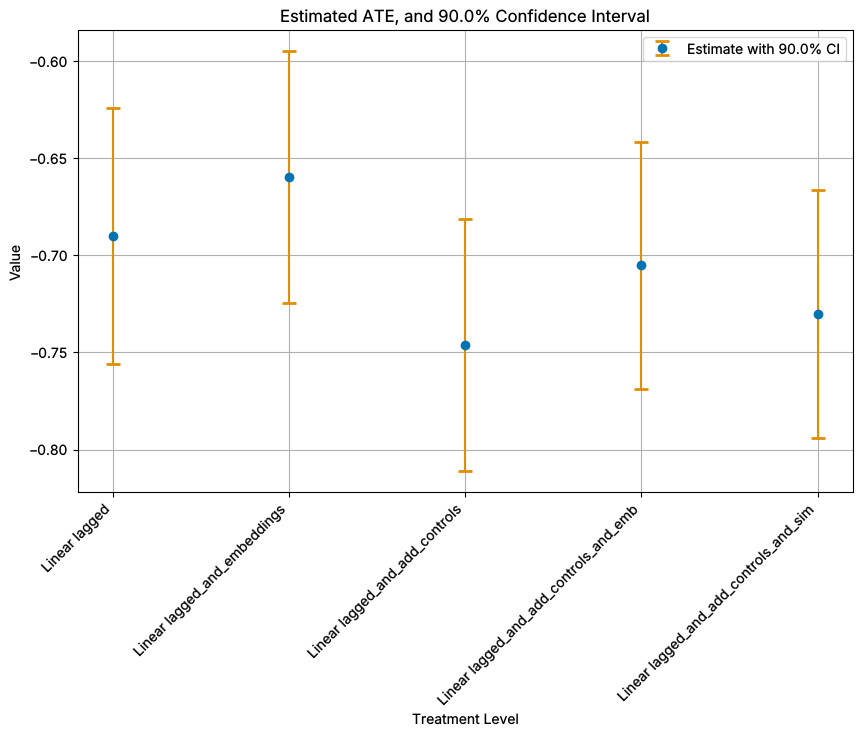

In [29]:
# Plotting
plt.figure(figsize=(10, 6))
# Plot Estimate with CI
plt.errorbar(
    df_base["model"],
    df_base["coef"],
    yerr=[df_base["coef"] - df_base["lower"], df_base["upper"] - df_base["coef"]],
    fmt="o",
    capsize=5,
    capthick=2,
    ecolor=palette[1],
    color=palette[0],
    label=f"Estimate with {round(confidence_level * 100, 1)}% CI",
    zorder=2,
)

plt.title(f"Estimated ATE, and {round(confidence_level * 100, 1)}% Confidence Interval")
plt.xlabel("Treatment Level")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_dir, f"linear_ate_estimates.png"), bbox_inches="tight")
plt.show()

In [30]:
df_base

,lower,upper,coef,model
0,-0.756093,-0.624438,-0.690266,Linear lagged
1,-0.724453,-0.595004,-0.659728,Linear lagged_and_embeddings
2,-0.811127,-0.681600,-0.746364,Linear lagged_and_add_controls
3,-0.768963,-0.641601,-0.705282,Linear lagged_and_add_controls_and_emb
4,-0.794199,-0.666514,-0.730356,Linear lagged_and_add_controls_and_sim


### DML Models

In [31]:
ml_g = LGBMRegressor(n_estimators=500, lr=0.02, random_state=42, verbose=-1)
ml_m = LGBMRegressor(n_estimators=500, lr=0.02, random_state=42, verbose=-1)


def r2(y_true, y_pred):
    subset = np.logical_not(np.isnan(y_true))
    return r2_score(y_true[subset], y_pred[subset])


def estimate_dml_model(controls):
    tab_dml_data = dml.DoubleMLClusterData(
        df_dynamic,
        y_col=outcome[0],
        d_cols=base_treatment,
        x_cols=controls,
        cluster_cols="ASIN",
    )

    np.random.seed(3141)
    tab_dml_obj = dml.DoubleMLPLR(tab_dml_data, ml_g, ml_m)
    tab_dml_obj.fit()

    tab_summary_df = summarize_dml(tab_dml_obj, level=confidence_level)
    ci_tab_dml = tab_summary_df[ci_names + ["coef"]]
    ci_tab_dml.columns = ["lower", "upper", "coef"]

    r2_scores = tab_dml_obj.evaluate_learners(metric=r2)
    print(
        f"R2 Outcome: {round(r2_scores['ml_l'][0, 0], 4)} R2 Treatment: {round(r2_scores['ml_m'][0, 0], 4)}\n"
    )

    return tab_dml_obj, ci_tab_dml

In [32]:
tab_dml_obj_embeddings, ci_tab_dml_embeddings = estimate_dml_model(
    controls=lag_1_vars + embeddings
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.642    0.042 -15.121    0.0 -0.712 -0.573
R2 Outcome: 0.873 R2 Treatment: 0.9743



In [33]:
tab_dml_obj_add_controls, ci_tab_dml_add_controls = estimate_dml_model(
    controls=lag_1_vars + additional_controls
)

        coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.69    0.041 -16.812    0.0 -0.758 -0.623
R2 Outcome: 0.8991 R2 Treatment: 0.9775



In [34]:
tab_dml_obj_embeddings_add_controls, ci_tab_dml_embeddings_add_controls = (
    estimate_dml_model(controls=lag_1_vars + embeddings + additional_controls)
)

         coef  std err      t  P>|t|   5.0%  95.0%
P_bb_t -0.677    0.039 -17.53    0.0 -0.741 -0.614
R2 Outcome: 0.8973 R2 Treatment: 0.9759



In [35]:
tab_dml_obj_sim_add_controls, ci_tab_dml_sim_add_controls = estimate_dml_model(
    controls=lag_1_vars + controls_similarities + additional_controls
)

         coef  std err      t  P>|t|   5.0%  95.0%
P_bb_t -0.701    0.039 -17.77    0.0 -0.765 -0.636
R2 Outcome: 0.9009 R2 Treatment: 0.977



In [36]:
tab_dml_obj_pca_add_controls, ci_tab_dml_pca_add_controls = estimate_dml_model(
    controls=lag_1_vars + controls_pca + additional_controls
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.697    0.039 -17.757    0.0 -0.761 -0.632
R2 Outcome: 0.9013 R2 Treatment: 0.9774



### Visualization

In [37]:
ci_tab_dml_embeddings["model"] = "plr_embeddings"
ci_tab_dml_add_controls["model"] = "plr_add_controls"
ci_tab_dml_embeddings_add_controls["model"] = "plr_embeddings_add_controls"
ci_tab_dml_sim_add_controls["model"] = "plr_sim_add_controls"
ci_tab_dml_pca_add_controls["model"] = "plr_pca_add_controls"


df_averages = pd.concat(
    [
        ci_tab_dml_embeddings,
        ci_tab_dml_add_controls,
        ci_tab_dml_embeddings_add_controls,
        ci_tab_dml_sim_add_controls,
        ci_tab_dml_pca_add_controls,
    ],
    ignore_index=True,
)

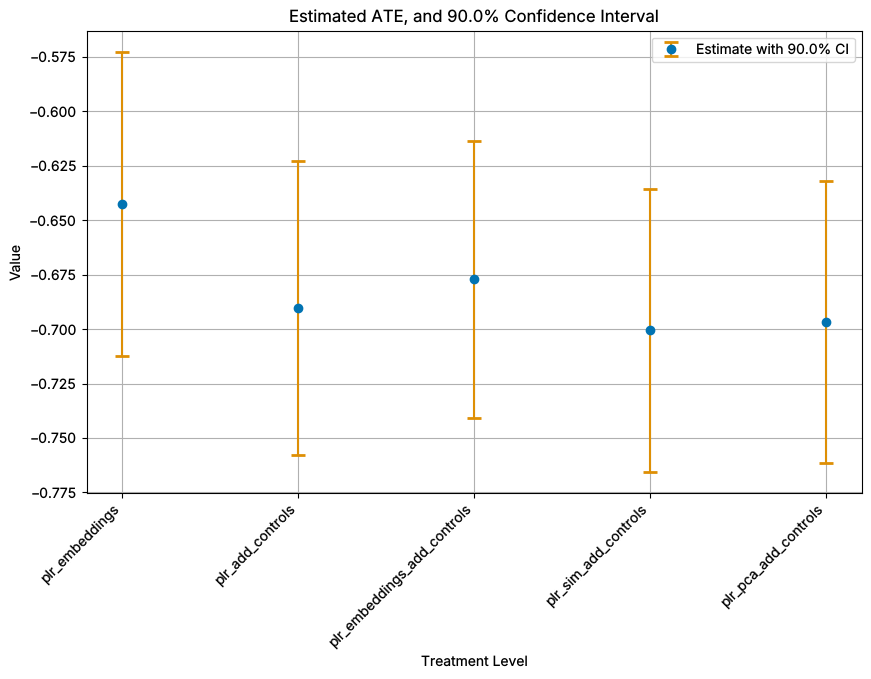

In [38]:
# Plotting
plt.figure(figsize=(10, 6))
# Plot Estimate with CI
plt.errorbar(
    df_averages["model"],
    df_averages["coef"],
    yerr=[
        df_averages["coef"] - df_averages["lower"],
        df_averages["upper"] - df_averages["coef"],
    ],
    fmt="o",
    capsize=5,
    capthick=2,
    ecolor=palette[1],
    color=palette[0],
    label=f"Estimate with {round(confidence_level * 100, 1)}% CI",
    zorder=2,
)

plt.title(f"Estimated ATE, and {round(confidence_level * 100, 1)}% Confidence Interval")
plt.xlabel("Treatment Level")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_dir, f"plr_ate_estimates.png"), bbox_inches="tight")
plt.show()

### Main Table of Homogeneous Effects

All rows of the table of estimated inverse-rank elasticities in the paper (Models I-1 to I-3) are taken from the estimation output above: the linear models are re-summarized with the same OLS specification and clustered covariance as in `estimate_linear_model`, the boosted-tree rows are taken from the fitted `DoubleMLPLR` objects. Confidence intervals are two-sided 90% intervals.

In [39]:
def summarize_linear_treatment(controls):
    x = sm.add_constant(df_dynamic[base_treatment + controls])
    results = sm.OLS(df_dynamic[outcome], x).fit(
        cov_type="cluster", cov_kwds={"groups": df_dynamic["ASIN"]}
    )
    ci = results.conf_int(alpha=1 - confidence_level).loc[base_treatment[0]]
    return {
        "coef": results.params[base_treatment[0]],
        "std err": results.bse[base_treatment[0]],
        "t": results.tvalues[base_treatment[0]],
        "P>|t|": results.pvalues[base_treatment[0]],
        "lower": ci.iloc[0],
        "upper": ci.iloc[1],
    }


def summarize_plr_treatment(dml_obj):
    ci = dml_obj.confint(level=confidence_level).iloc[0]
    return {
        "coef": dml_obj.coef[0],
        "std err": dml_obj.se[0],
        "t": dml_obj.t_stat[0],
        "P>|t|": dml_obj.pval[0],
        "lower": ci.iloc[0],
        "upper": ci.iloc[1],
    }


main_table_specs = [
    ("I-1. Linear ($P_{t-1}$, $Q_{t-1}$)", summarize_linear_treatment(lag_1_vars), ci_linear_base_lagged),
    (
        "I-1. Linear ($P_{t-1}$, $Q_{t-1}$, $X^{e}, X^{o}_t$)",
        summarize_linear_treatment(lag_1_vars + additional_controls + embeddings),
        ci_linear_base_lagged_add_controls_emb,
    ),
    (
        "I-1. Linear ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)",
        summarize_linear_treatment(lag_1_vars + controls_similarities + additional_controls),
        ci_linear_base_lagged_add_controls_sim,
    ),
    (
        "I-2. Linear with Interactions ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)",
        summarize_linear_treatment(interaction_vars + controls_similarities + additional_controls),
        ci_linear_interactions,
    ),
    (
        "I-3. Boosted Trees ($P_{t-1}$, $Q_{t-1}$, $X^{e}, X^{o}_t$)",
        summarize_plr_treatment(tab_dml_obj_embeddings_add_controls),
        ci_tab_dml_embeddings_add_controls,
    ),
    (
        "I-3. Boosted Trees ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)",
        summarize_plr_treatment(tab_dml_obj_sim_add_controls),
        ci_tab_dml_sim_add_controls,
    ),
]

rows = []
for label, row, estimate in main_table_specs:
    # identical to the estimates reported above
    for col in ["coef", "lower", "upper"]:
        assert np.isclose(row[col], np.asarray(estimate[col])[0], rtol=0, atol=1e-12), (label, col)
    rows.append({"specification": label, **row})
df_main_table = pd.DataFrame(rows).set_index("specification")
df_main_table.to_csv(os.path.join(output_dir, "homogeneous_elasticity_estimates.csv"))
df_main_table.round(3)

,coef,std err,t,P>|t|,lower,upper
specification,,,,,,
"I-1. Linear ($P_{t-1}$, $Q_{t-1}$)",-0.690,0.040,-17.248,0.0,-0.756,-0.624
"I-1. Linear ($P_{t-1}$, $Q_{t-1}$, $X^{e}, X^{o}_t$)",-0.705,0.039,-18.217,0.0,-0.769,-0.642
"I-1. Linear ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)",-0.730,0.039,-18.817,0.0,-0.794,-0.667
"I-2. Linear with Interactions ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)",-0.731,0.039,-18.690,0.0,-0.795,-0.667
"I-3. Boosted Trees ($P_{t-1}$, $Q_{t-1}$, $X^{e}, X^{o}_t$)",-0.677,0.039,-17.530,0.0,-0.741,-0.614
"I-3. Boosted Trees ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)",-0.701,0.039,-17.770,0.0,-0.765,-0.636


In [40]:
def format_p_value(p):
    return "\\textless 0.001" if p < 0.001 else f"{p:.3f}"


latex_rows = [
    f"{{{label}}} & {r['coef']:.3f} & {r['std err']:.3f} & {r['t']:.3f} & {format_p_value(r['P>|t|'])} "
    f"& {r['lower']:.3f} & {r['upper']:.3f}\\\\"
    for label, r in df_main_table.iterrows()
]
latex_main_table = "\n".join(latex_rows)
with open(os.path.join(output_dir, "homogeneous_elasticity_estimates.tex"), "w") as f:
    f.write(latex_main_table + "\n")
print(latex_main_table)

{I-1. Linear ($P_{t-1}$, $Q_{t-1}$)} & -0.690 & 0.040 & -17.248 & \textless 0.001 & -0.756 & -0.624\\
{I-1. Linear ($P_{t-1}$, $Q_{t-1}$, $X^{e}, X^{o}_t$)} & -0.705 & 0.039 & -18.217 & \textless 0.001 & -0.769 & -0.642\\
{I-1. Linear ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)} & -0.730 & 0.039 & -18.817 & \textless 0.001 & -0.794 & -0.667\\
{I-2. Linear with Interactions ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)} & -0.731 & 0.039 & -18.690 & \textless 0.001 & -0.795 & -0.667\\
{I-3. Boosted Trees ($P_{t-1}$, $Q_{t-1}$, $X^{e}, X^{o}_t$)} & -0.677 & 0.039 & -17.530 & \textless 0.001 & -0.741 & -0.614\\
{I-3. Boosted Trees ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)} & -0.701 & 0.039 & -17.770 & \textless 0.001 & -0.765 & -0.636\\


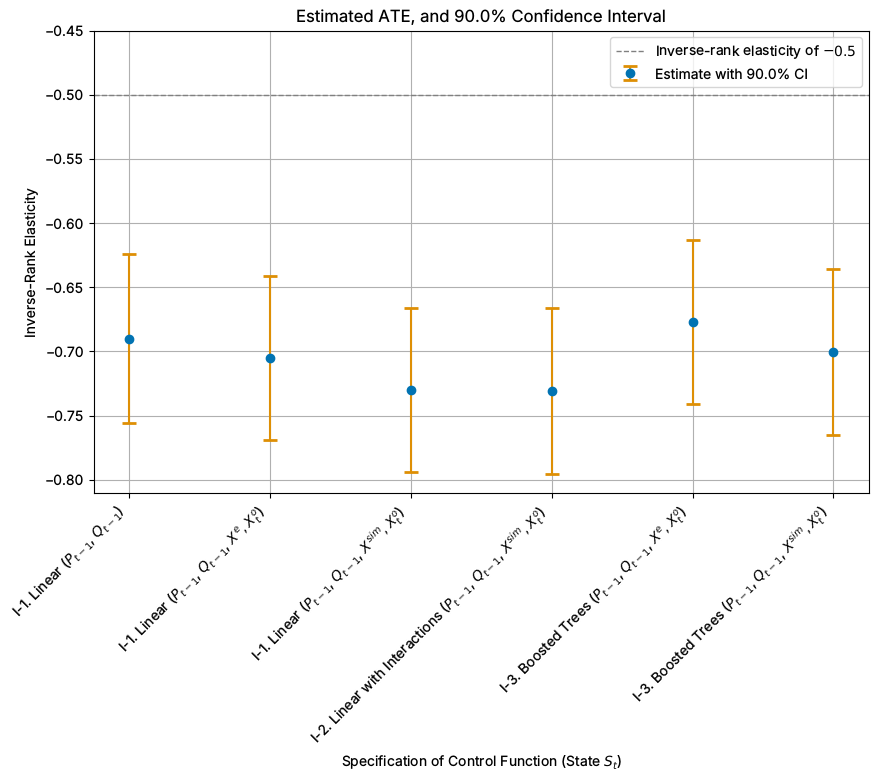

In [41]:
x_vals = np.arange(len(df_main_table))

plt.figure(figsize=(10, 6))
plt.errorbar(
    x_vals,
    df_main_table["coef"],
    yerr=[
        df_main_table["coef"] - df_main_table["lower"],
        df_main_table["upper"] - df_main_table["coef"],
    ],
    fmt="o",
    capsize=5,
    capthick=2,
    ecolor=palette[1],
    color=palette[0],
    label=f"Estimate with {round(confidence_level * 100, 1)}% CI",
    zorder=2,
)
plt.axhline(-0.5, color="gray", linestyle="--", linewidth=1, label="Inverse-rank elasticity of $-0.5$")
plt.title(f"Estimated ATE, and {round(confidence_level * 100, 1)}% Confidence Interval")
plt.xlabel("Specification of Control Function (State $S_t$)")
plt.xticks(x_vals, df_main_table.index, rotation=45, ha="right")
plt.ylabel("Inverse-Rank Elasticity")
plt.ylim(top=-0.45)
plt.legend(loc="upper right")
plt.grid(True)
plt.savefig(os.path.join(output_dir, "homogeneous_elasticity_estimates.png"), bbox_inches="tight")
plt.show()

## GATEs

0
similarity_cluster_0    11540
similarity_cluster_1     7251
similarity_cluster_2     4372
similarity_cluster_3     7229
similarity_cluster_4     7649
dtype: int64


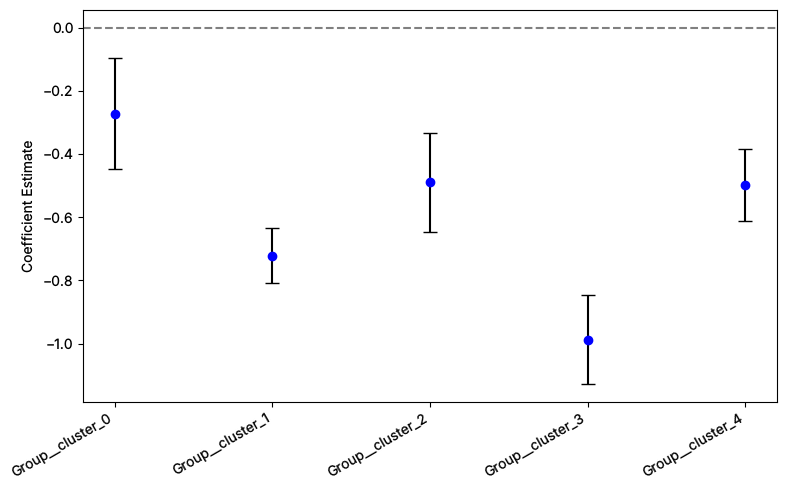

In [42]:
groups = pd.DataFrame(
    df_dynamic[
        [
            "similarity_cluster_0",
            "similarity_cluster_1",
            "similarity_cluster_2",
            "similarity_cluster_3",
            "similarity_cluster_4",
        ]
    ].idxmax(axis=1)
)

print(groups.groupby(0).size())
gates_0 = tab_dml_obj_embeddings.gate(groups)
gates_0_summ = gates_0.summary
gates_0_summ["err_lower"] = gates_0_summ["coef"] - gates_0_summ["[0.025"]
gates_0_summ["err_upper"] = gates_0_summ["0.975]"] - gates_0_summ["coef"]

# Positions on the x-axis
x_vals = range(len(gates_0_summ))

plt.figure(figsize=(8, 5))
plt.errorbar(
    x=x_vals,
    y=gates_0_summ["coef"],
    yerr=[gates_0_summ["err_lower"], gates_0_summ["err_upper"]],
    fmt="o",
    capsize=5,
    color="blue",
    ecolor="black",
)

# Draw a zero line for reference
plt.axhline(y=0, color="gray", linestyle="--")

# Customizing x-axis labels
plt.xticks(
    ticks=x_vals,
    labels=[gr.replace("similarity", "") for gr in gates_0_summ.index],
    rotation=30,
    ha="right",
)
plt.ylabel("Coefficient Estimate")
plt.tight_layout()
plt.show()

## CATEs

In [43]:
uniform_ci = True  # False | True

In [44]:
cate_controls = lag_1_vars + embeddings + additional_controls
cate_controls_interactions = cate_controls + interaction_vars

plr_obj = tab_dml_obj_embeddings_add_controls

In [45]:
import gc

gc.collect()

20112

In [46]:
cate_kwargs_val = {"cov_type": "cluster", "cov_kwds": {"groups": df_dynamic["ASIN"]}}

cate_models_polynomial = {
    "Linear Specification": None,
    "Linear Specification (Interactions)": None,
    "PLR Specification": None,
}

# Linear Models
cate_models_polynomial["Linear Specification"] = lin_model_cate(
    df=df_dynamic,
    outcome=outcome,
    basis=df_basis,
    treatment=base_treatment,
    controls=cate_controls,
    **cate_kwargs_val,
)

print(f"\nLinear Specification")
df_specification_1 = summarize_lin_model(
    cate_models_polynomial["Linear Specification"], level=confidence_level
)
print("=" * 80)  #

cate_models_polynomial["Linear Specification (Interactions)"] = lin_model_cate(
    df=df_dynamic,
    outcome=outcome,
    basis=df_basis,
    treatment=base_treatment,
    controls=cate_controls_interactions,
    **cate_kwargs_val,
)

print(f"\nLinear specification with interactions")
df_specification_2 = summarize_lin_model(
    cate_models_polynomial["Linear Specification (Interactions)"],
    level=confidence_level,
)
print("=" * 80)

# tabular DML model
cate_models_polynomial["PLR Specification"] = plr_obj.cate(df_basis, **cate_kwargs_val)

print(f"\nTabular DML PLR Specification")
df_specification_3 = summarize_lin_model(
    cate_models_polynomial["PLR Specification"].blp_model, level=confidence_level
)
print("=" * 80)


Linear Specification
                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.667    0.042 -15.944  0.000 -0.736 -0.598
Q_t-1                -0.184    0.052  -3.561  0.000 -0.269 -0.099
P_bb_t-1             -0.006    0.049  -0.122  0.903 -0.086  0.075
similarity_cluster_0 -2.547    2.057  -1.238  0.216 -5.929  0.836
similarity_cluster_1 -2.618    1.802  -1.452  0.146 -5.582  0.347
similarity_cluster_2 -1.427    1.321  -1.081  0.280 -3.600  0.745
similarity_cluster_3 -2.124    1.464  -1.450  0.147 -4.532  0.285
similarity_cluster_4 -2.514    1.881  -1.336  0.181 -5.609  0.580



Linear specification with interactions
                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.676    0.042 -16.171  0.000 -0.745 -0.607
Q_t-1                -0.202    0.051  -3.960  0.000 -0.286 -0.118
P_bb_t-1             -0.019    0.050  -0.372  0.710 -0.100  0.063
similarity_cluster_0 -2.407    2.071  -1.162  0.245 -5.813  0.999
similarity_cluster_1 -2.537    1.815  -1.398  0.162 -5.523  0.448
similarity_cluster_2 -1.340    1.329  -1.008  0.314 -3.526  0.847
similarity_cluster_3 -1.995    1.476  -1.352  0.176 -4.422  0.432
similarity_cluster_4 -2.353    1.897  -1.241  0.215 -5.473  0.766

Tabular DML PLR Specification
                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.684    0.040 -17.006  0.000 -0.751 -0.618
Q_t-1                -0.263    0.061  -4.289  0.000 -0.363 -0.162
P_bb_t-1             -0.031    0.031  -0.989  0.323 -0.082  0.020
similarity_cluster_0 -5.289    1.918  -2.758  0.006 -8.443 -2.134
simil

In [47]:
cate_models_polynomial["Linear Specification (Interactions)"].summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.024
Model:                            OLS   Adj. R-squared (uncentered):              0.024
Method:                 Least Squares   F-statistic:                              58.18
Date:                Thu, 22 Oct 2026   Prob (F-statistic):                    9.19e-90
Time:                        00:58:52   Log-Likelihood:                         -20922.
No. Observations:               38041   AIC:                                  4.186e+04
Df Residuals:                   38033   BIC:                                  4.193e+04
Df Model:                           8                                                  
Covariance Type:              cluster                                                  
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
intercept               -0.6762      0.042    -16.171      0.000      -0.758      -0.594
Q_t-1                   -0.2021      0.051     -3.960      0.000      -0.302      -0.102
P_bb_t-1                -0.0185      0.050     -0.372      0.710      -0.116       0.079
similarity_cluster_0    -2.4070      2.071     -1.162      0.245      -6.465       1.651
similarity_cluster_1    -2.5374      1.815     -1.398      0.162      -6.095       1.020
similarity_cluster_2    -1.3395      1.329     -1.008      0.314      -3.945       1.266
similarity_cluster_3    -1.9948      1.476     -1.352      0.176      -4.887       0.897
similarity_cluster_4    -2.3532      1.897     -1.241      0.215      -6.070       1.364
==============================================================================
Omnibus:                    12242.511   Durbin-Watson:                   1.988
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           697825.031
Skew:                           0.744   Prob(JB):                         0.00
Kurtosis:                      23.929   Cond. No.                         121.
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors are robust to cluster correlation (cluster)
"""

In [48]:
cate_models_polynomial["PLR Specification"].blp_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.029
Model:                            OLS   Adj. R-squared (uncentered):              0.028
Method:                 Least Squares   F-statistic:                              59.13
Date:                Thu, 22 Oct 2026   Prob (F-statistic):                    3.28e-91
Time:                        00:58:52   Log-Likelihood:                         -20634.
No. Observations:               38041   AIC:                                  4.128e+04
Df Residuals:                   38033   BIC:                                  4.135e+04
Df Model:                           8                                                  
Covariance Type:              cluster                                                  
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
intercept               -0.6845      0.040    -17.006      0.000      -0.763      -0.606
Q_t-1                   -0.2627      0.061     -4.289      0.000      -0.383      -0.143
P_bb_t-1                -0.0306      0.031     -0.989      0.323      -0.091       0.030
similarity_cluster_0    -5.2887      1.918     -2.758      0.006      -9.047      -1.530
similarity_cluster_1    -4.9245      1.683     -2.925      0.003      -8.224      -1.625
similarity_cluster_2    -3.3592      1.251     -2.685      0.007      -5.811      -0.907
similarity_cluster_3    -4.0737      1.364     -2.986      0.003      -6.747      -1.400
similarity_cluster_4    -4.8223      1.777     -2.713      0.007      -8.306      -1.339
==============================================================================
Omnibus:                    15540.175   Durbin-Watson:                   1.594
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           568467.886
Skew:                           1.298   Prob(JB):                         0.00
Kurtosis:                      21.759   Cond. No.                         203.
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors are robust to cluster correlation (cluster)
"""

In [49]:
latex_args = {
    "index": True,
    "float_format": "%.3f",
    "column_format": "lcccccc",
}

print(df_specification_1.to_latex(**latex_args))
print(df_specification_2.to_latex(**latex_args))
print(df_specification_3.to_latex(**latex_args))

\begin{tabular}{lcccccc}
\toprule
 & coef & std err & t & P>|t| & 5.0% & 95.0% \\
\midrule
intercept & -0.667 & 0.042 & -15.944 & 0.000 & -0.736 & -0.598 \\
Q_t-1 & -0.184 & 0.052 & -3.561 & 0.000 & -0.269 & -0.099 \\
P_bb_t-1 & -0.006 & 0.049 & -0.122 & 0.903 & -0.086 & 0.075 \\
similarity_cluster_0 & -2.547 & 2.057 & -1.238 & 0.216 & -5.929 & 0.836 \\
similarity_cluster_1 & -2.618 & 1.802 & -1.452 & 0.146 & -5.582 & 0.347 \\
similarity_cluster_2 & -1.427 & 1.321 & -1.081 & 0.280 & -3.600 & 0.745 \\
similarity_cluster_3 & -2.124 & 1.464 & -1.450 & 0.147 & -4.532 & 0.285 \\
similarity_cluster_4 & -2.514 & 1.881 & -1.336 & 0.181 & -5.609 & 0.580 \\
\bottomrule
\end{tabular}

\begin{tabular}{lcccccc}
\toprule
 & coef & std err & t & P>|t| & 5.0% & 95.0% \\
\midrule
intercept & -0.676 & 0.042 & -16.171 & 0.000 & -0.745 & -0.607 \\
Q_t-1 & -0.202 & 0.051 & -3.960 & 0.000 & -0.286 & -0.118 \\
P_bb_t-1 & -0.019 & 0.050 & -0.372 & 0.710 & -0.100 & 0.063 \\
similarity_cluster_0 & -2.407 & 2.07

In [50]:
summary_list = []
for model_name, model in cate_models_polynomial.items():
    if "Linear" in model_name:
        tmp_summary = summarize_lin_model(model, level=confidence_level)
    else:
        tmp_summary = summarize_lin_model(model.blp_model, level=confidence_level)
    for index, row in tmp_summary.iterrows():
        variable = index
        summary_list.append(
            {
                "model": model_name,
                "variable": variable,
                "coef": row["coef"],
                "Std.Err.": row["std err"],
                "lower": row[ci_names[0]],  # Adjusted to match the column name
                "upper": row[ci_names[1]],  # Adjusted to match the column name
            }
        )

cate_summary_df = pd.DataFrame(summary_list)

                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.667    0.042 -15.944  0.000 -0.736 -0.598
Q_t-1                -0.184    0.052  -3.561  0.000 -0.269 -0.099
P_bb_t-1             -0.006    0.049  -0.122  0.903 -0.086  0.075
similarity_cluster_0 -2.547    2.057  -1.238  0.216 -5.929  0.836
similarity_cluster_1 -2.618    1.802  -1.452  0.146 -5.582  0.347
similarity_cluster_2 -1.427    1.321  -1.081  0.280 -3.600  0.745
similarity_cluster_3 -2.124    1.464  -1.450  0.147 -4.532  0.285
similarity_cluster_4 -2.514    1.881  -1.336  0.181 -5.609  0.580
                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.676    0.042 -16.171  0.000 -0.745 -0.607
Q_t-1                -0.202    0.051  -3.960  0.000 -0.286 -0.118
P_bb_t-1             -0.019    0.050  -0.372  0.710 -0.100  0.063
similarity_cluster_0 -2.407    2.071  -1.162  0.245 -5.813  0.999
similarity_cluster_1 -2.537    1.815  -1.398  0.162 -5.523  0.448
similarity

In [51]:
cate_summary_df

,model,variable,coef,Std.Err.,lower,upper
0,Linear Specification,intercept,-0.667034,0.041836,-0.735848,-0.598220
1,Linear Specification,Q_t-1,-0.183812,0.051612,-0.268706,-0.098919
2,Linear Specification,P_bb_t-1,-0.005980,0.048936,-0.086473,0.074513
3,Linear Specification,similarity_cluster_0,-2.546733,2.056552,-5.929460,0.835994
4,Linear Specification,similarity_cluster_1,-2.617639,1.802319,-5.582190,0.346912
5,Linear Specification,similarity_cluster_2,-1.427334,1.320904,-3.600027,0.745360
6,Linear Specification,similarity_cluster_3,-2.123808,1.464371,-4.532485,0.284868
7,Linear Specification,similarity_cluster_4,-2.514050,1.881333,-5.608567,0.580467
8,Linear Specification (Interactions),intercept,-0.676174,0.041814,-0.744952,-0.607396
9,Linear Specification (Interactions),Q_t-1,-0.202105,0.051032,-0.286046,-0.118164


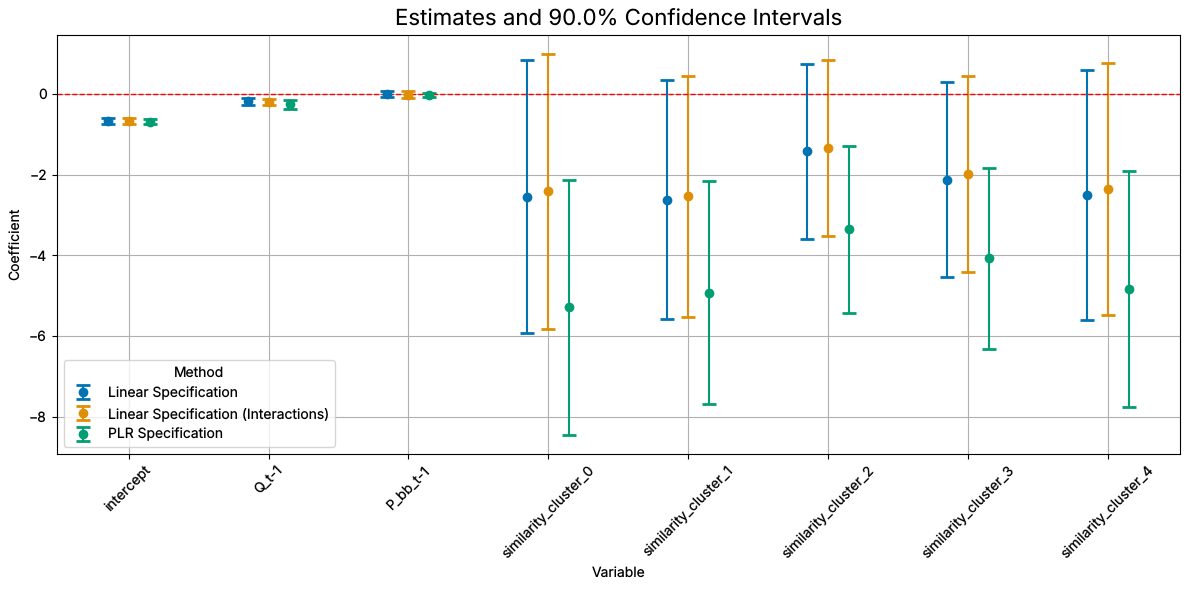

In [52]:
models = cate_summary_df["model"].unique()
variables = cate_summary_df["variable"].unique()
plt.figure(figsize=(12, 6))
bar_width = 0.15
x_positions = np.arange(len(variables))
for i, model in enumerate(models):
    df_model = cate_summary_df[cate_summary_df["model"] == model]
    if not df_model.empty:
        plt.errorbar(
            x_positions + i * bar_width,
            df_model["coef"],
            yerr=[
                df_model["coef"] - df_model["lower"],
                df_model["upper"] - df_model["coef"],
            ],
            fmt="o",
            label=model,
            capsize=5,
            capthick=2,
            ecolor=palette[i % len(palette)],
            color=palette[i % len(palette)],
            zorder=2,
        )
plt.xticks(x_positions + (len(models) - 1) * bar_width / 2, variables, rotation=45)
plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.title(f"Estimates and {ci_level_name} Confidence Intervals", fontsize=16)
plt.xlabel("Variable")
plt.ylabel("Coefficient")
plt.legend(title="Method")
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"cluster_and_level_cate_estimates.png"))
plt.show()

### $R^2$

In [53]:
alpha_x_lin = cate_models_polynomial["Linear Specification"].predict(df_basis)
alpha_x_lin_interactions = cate_models_polynomial[
    "Linear Specification (Interactions)"
].predict(df_basis)
alpha_x_plr = cate_models_polynomial["PLR Specification"].blp_model.predict(df_basis)


print("Linear Specification")
model_lin_emb = sm.OLS(alpha_x_lin, sm.add_constant(df_dynamic[embeddings])).fit()
model_lin_sim = sm.OLS(
    alpha_x_lin, sm.add_constant(df_dynamic[controls_similarities])
).fit()
model_lin_lvl = sm.OLS(alpha_x_lin, sm.add_constant(df_dynamic[lag_1_vars])).fit()

print("Variance explained by embeddings: ", model_lin_emb.rsquared)
print("Variance explained by similarities: ", model_lin_sim.rsquared)
print("Variance explained by lagged variables: ", model_lin_lvl.rsquared)

print("Linear Specification with interactions")
model_lin_interactions_emb = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[embeddings])
).fit()
model_lin_interactions_sim = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[controls_similarities])
).fit()
model_lin_interactions_lvl = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[lag_1_vars])
).fit()
print("Variance explained by embeddings: ", model_lin_interactions_emb.rsquared)
print("Variance explained by similarities: ", model_lin_interactions_sim.rsquared)
print("Variance explained by lagged variables: ", model_lin_interactions_lvl.rsquared)

print("PLR Specification")
model_plr_emb = sm.OLS(alpha_x_plr, sm.add_constant(df_dynamic[embeddings])).fit()
model_plr_sim = sm.OLS(
    alpha_x_plr, sm.add_constant(df_dynamic[controls_similarities])
).fit()
model_plr_lvl = sm.OLS(alpha_x_plr, sm.add_constant(df_dynamic[lag_1_vars])).fit()
print("Variance explained by embeddings: ", model_plr_emb.rsquared)
print("Variance explained by similarities: ", model_plr_sim.rsquared)
print("Variance explained by lagged variables: ", model_plr_lvl.rsquared)

Linear Specification


Variance explained by embeddings:  0.6719596393944766
Variance explained by similarities:  0.542235675732702
Variance explained by lagged variables:  0.6711003343327742
Linear Specification with interactions


Variance explained by embeddings:  0.6417556248494557
Variance explained by similarities:  0.501309645856348
Variance explained by lagged variables:  0.6943256141452713
PLR Specification


Variance explained by embeddings:  0.5759830806227513
Variance explained by similarities:  0.4104140319337376
Variance explained by lagged variables:  0.7450240027230659


## $\Chi^2$ Test

In [54]:
# select index with cluster similarity
cluster_treatment_ids = [
    i for i, variable in enumerate(df_basis.columns) if "similarity_cluster" in variable
]
cluster_treatment_ids

[3, 4, 5, 6, 7]

In [55]:
lin_p_val = chi2_test(
    cate_models_polynomial["Linear Specification"], cluster_treatment_ids
)
lin_interactions_p_val = chi2_test(
    cate_models_polynomial["Linear Specification (Interactions)"], cluster_treatment_ids
)
tab_dml_p_val = chi2_test(
    cate_models_polynomial["PLR Specification"], cluster_treatment_ids
)

print(f"Linear Specification p-value: {lin_p_val} (sample size: {len(df_dynamic)})")
print(
    f"Linear Specification (Interactions) p-value: {lin_interactions_p_val} (sample size: {len(df_dynamic)})"
)
print(f"PLR Specification p-value: {tab_dml_p_val} (sample size: {len(df_dynamic)})")

Linear Specification p-value: 0.02441101986864269 (sample size: 38041)
Linear Specification (Interactions) p-value: 0.018609970083883876 (sample size: 38041)
PLR Specification p-value: 0.004363675147414425 (sample size: 38041)


In [56]:
het_ids = [1, 2, 3, 4, 5, 6, 7]

lin_p_val = chi2_test(cate_models_polynomial["Linear Specification"], het_ids)
lin_interactions_p_val = chi2_test(
    cate_models_polynomial["Linear Specification (Interactions)"], het_ids
)
tab_dml_p_val = chi2_test(cate_models_polynomial["PLR Specification"], het_ids)

print(f"Linear Specification p-value: {lin_p_val} (sample size: {len(df_dynamic)})")
print(
    f"Linear Specification (Interactions) p-value: {lin_interactions_p_val} (sample size: {len(df_dynamic)})"
)
print(f"PLR Specification p-value: {tab_dml_p_val} (sample size: {len(df_dynamic)})")

Linear Specification p-value: 1.5941863184432137e-05 (sample size: 38041)
Linear Specification (Interactions) p-value: 4.345283109885578e-06 (sample size: 38041)
PLR Specification p-value: 5.637708290207044e-07 (sample size: 38041)


## Sorted Effects

In [57]:
treatment_ids = [0, 1, 2] + cluster_treatment_ids
df_basis_sorted = df_basis.iloc[:, treatment_ids]  # .join(df_dynamic[["ASIN", "date"]])

In [58]:
df_basis_sorted

,intercept,Q_t-1,P_bb_t-1,similarity_cluster_0,similarity_cluster_1,similarity_cluster_2,similarity_cluster_3,similarity_cluster_4
0,1.0,0.305280,0.463601,-0.102049,0.058408,0.057394,0.069051,-0.042671
1,1.0,0.272505,0.653600,-0.102049,0.058408,0.057394,0.069051,-0.042671
2,1.0,0.036240,0.687961,-0.102049,0.058408,0.057394,0.069051,-0.042671
3,1.0,0.025283,0.636881,-0.102049,0.058408,0.057394,0.069051,-0.042671
4,1.0,-0.051370,0.556816,-0.102049,0.058408,0.057394,0.069051,-0.042671
...,...,...,...,...,...,...,...,...
38036,1.0,0.009068,0.478593,0.280532,-0.310489,-0.119207,-0.057372,0.102452
38037,1.0,-0.393270,-0.753352,0.047400,0.133878,0.254117,-0.105317,-0.273444
38038,1.0,-0.277916,-0.753352,0.059229,0.142991,0.265195,-0.100101,-0.307921
38039,1.0,1.267533,-1.535804,0.440349,0.042304,0.029734,-0.129491,-0.478517


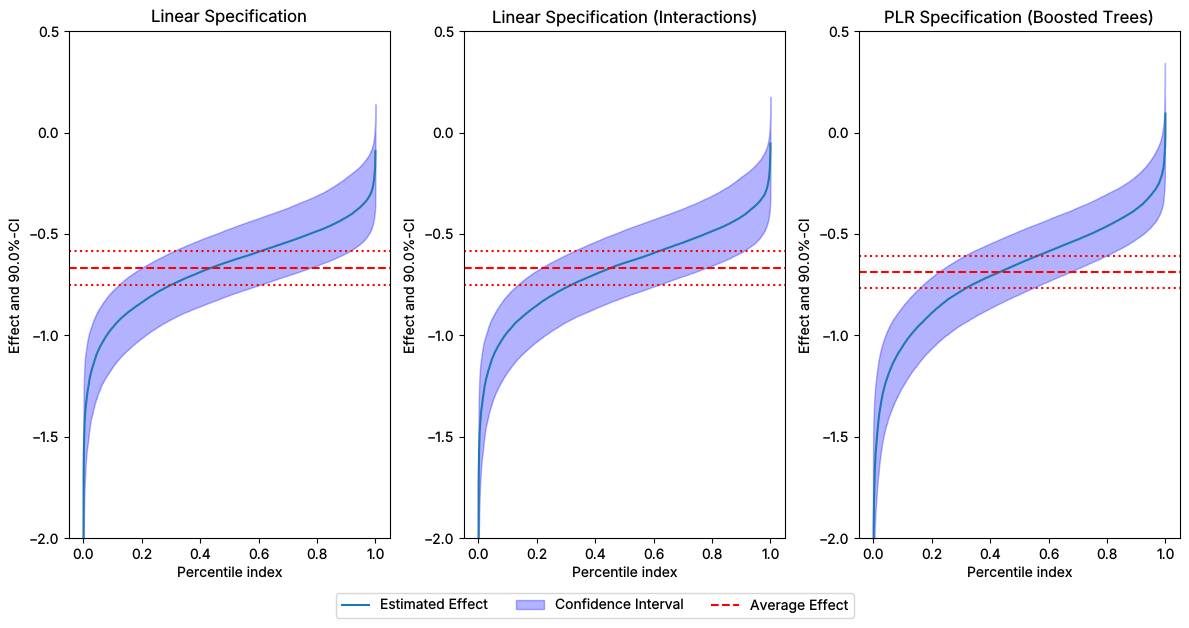

In [59]:
uniform_ci = False

plt.rcParams["figure.figsize"] = (
    15.0,
    7.5,
)  # Adjusted the figure size for side-by-side plots
# Determine the number of models to plot
num_plots = 1
# Create subplots with cate_vars as rows and models as columns
fig, axs = plt.subplots(nrows=num_plots, ncols=3, figsize=(12, 6 * num_plots))
# If there's only one model, axs won't be a list, so wrap it in a list
if num_plots == 1:
    axs = np.array([axs, axs])  # Create a 2-column array


# Linear model
df_lin_ci_pointwise = predict_cate(
    cate_models_polynomial["Linear Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_lin_ci_pointwise_sorted = df_lin_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_lin_ci_uniform = predict_cate(
    cate_models_polynomial["Linear Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_lin_ci_uniform_sorted = df_lin_ci_uniform.apply(
    lambda x: x.sort_values().values, axis=0
)
lm_intercept = cate_models_polynomial["Linear Specification"].params["intercept"]
lm_intercept_ci = (
    cate_models_polynomial["Linear Specification"].conf_int().loc["intercept"]
)

# Tabular DML model
df_tab_dml_ci_pointwise = predict_cate(
    cate_models_polynomial["Linear Specification (Interactions)"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_tab_dml_ci_pointwise_sorted = df_tab_dml_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_tab_dml_ci_joint = predict_cate(
    cate_models_polynomial["Linear Specification (Interactions)"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_tab_dml_ci_joint_sorted = df_tab_dml_ci_joint.apply(
    lambda x: x.sort_values().values, axis=0
)

tab_dml_intercept = cate_models_polynomial["Linear Specification"].params["intercept"]
tab_dml_intercept_ci = (
    cate_models_polynomial["Linear Specification"].conf_int().loc["intercept"]
)

# PLR Model
df_deep_dml_ci_pointwise = predict_cate(
    cate_models_polynomial["PLR Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_deep_dml_ci_pointwise_sorted = df_deep_dml_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_deep_dml_ci_joint = predict_cate(
    cate_models_polynomial["PLR Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_deep_dml_ci_joint_sorted = df_deep_dml_ci_joint.apply(
    lambda x: x.sort_values().values, axis=0
)
deep_dml_intercept = cate_models_polynomial["PLR Specification"].blp_model.params[
    "intercept"
]
deep_dml_intercept_ci = (
    cate_models_polynomial["PLR Specification"].blp_model.conf_int().loc["intercept"]
)

# Calculate the y-axis limits for this row
y_min = min(
    df_lin_ci_pointwise[ci_names[0]].min(),
    df_lin_ci_uniform[ci_names[0]].min(),
    df_tab_dml_ci_pointwise[ci_names[0]].min(),
    df_tab_dml_ci_joint[ci_names[0]].min(),
    df_deep_dml_ci_pointwise[ci_names[0]].min(),
    df_deep_dml_ci_joint[ci_names[0]].min(),
)
y_max = max(
    df_lin_ci_pointwise[ci_names[1]].max(),
    df_lin_ci_uniform[ci_names[1]].max(),
    df_tab_dml_ci_pointwise[ci_names[1]].max(),
    df_tab_dml_ci_joint[ci_names[1]].max(),
    df_deep_dml_ci_pointwise[ci_names[1]].max(),
    df_deep_dml_ci_joint[ci_names[1]].max(),
)

# further adjust y-axis limits
y_min = max(y_min, -2)
y_max = min(y_max, 0.5)
percentiles_idx = np.linspace(0, 1, df_dynamic.shape[0])
percentiles_idx_full = np.linspace(0, 1, df_dynamic.shape[0])
# Plot on the first column
i = 0
ax0 = axs[i, 0]
ax0.plot(
    percentiles_idx_full, df_lin_ci_pointwise_sorted["effect"], label="Estimated Effect"
)
ax0.fill_between(
    percentiles_idx_full,
    df_lin_ci_pointwise_sorted[ci_names[0]],
    df_lin_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax0.fill_between(
        percentiles_idx_full,
        df_lin_ci_uniform_sorted[ci_names[0]],
        df_lin_ci_uniform_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax0.axhline(y=lm_intercept, color="r", linestyle="--", label="ATE")
ax0.axhline(y=lm_intercept_ci[0], color="r", linestyle="dotted")
ax0.axhline(y=lm_intercept_ci[1], color="r", linestyle="dotted")
ax0.set_title("Linear Specification")
ax0.set_xlabel("Percentile index")
ax0.set_ylabel(f"Effect and {ci_level_name}-CI")
ax0.set_ylim(y_min, y_max)
ax1 = axs[i, 1]
ax1.plot(
    percentiles_idx_full,
    df_tab_dml_ci_pointwise_sorted["effect"],
    label="Estimated Effect",
)
ax1.fill_between(
    percentiles_idx_full,
    df_tab_dml_ci_pointwise_sorted[ci_names[0]],
    df_tab_dml_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax1.fill_between(
        percentiles_idx_full,
        df_tab_dml_ci_joint_sorted[ci_names[0]],
        df_tab_dml_ci_joint_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax1.axhline(y=tab_dml_intercept, color="r", linestyle="--", label="Average Effect")
ax1.axhline(y=tab_dml_intercept_ci[0], color="r", linestyle="dotted")
ax1.axhline(y=tab_dml_intercept_ci[1], color="r", linestyle="dotted")
ax1.set_title("Linear Specification (Interactions)")
ax1.set_xlabel("Percentile index")
ax1.set_ylabel(f"Effect and {ci_level_name}-CI")
ax1.set_ylim(y_min, y_max)

ax2 = axs[i, 2]
ax2.plot(
    percentiles_idx_full,
    df_deep_dml_ci_pointwise_sorted["effect"],
    label="Estimated Effect",
)
ax2.fill_between(
    percentiles_idx_full,
    df_deep_dml_ci_pointwise_sorted[ci_names[0]],
    df_deep_dml_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax2.fill_between(
        percentiles_idx_full,
        df_deep_dml_ci_joint_sorted[ci_names[0]],
        df_deep_dml_ci_joint_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax2.axhline(y=deep_dml_intercept, color="r", linestyle="--", label="Average Effect")
ax2.axhline(y=deep_dml_intercept_ci[0], color="r", linestyle="dotted")
ax2.axhline(y=deep_dml_intercept_ci[1], color="r", linestyle="dotted")

ax2.set_title("PLR Specification (Boosted Trees)")
ax2.set_xlabel("Percentile index")
ax2.set_ylabel(f"Effect and {ci_level_name}-CI")
ax2.set_ylim(y_min, y_max)

# Create a single legend for all plots and place it at the lower center
handles, labels = axs[
    -1, 1 
].get_legend_handles_labels()  # Collect handles and labels from the last subplot
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.05), ncol=4)
# Adjust layout to make space for the legend
plt.tight_layout(rect=[0, 0.0, 1, 1])  # Leave space at the bottom for the legend

# Save the figure with tight bounding box to include the legend
plt.savefig(os.path.join(output_dir, "cluster_sorted_effects.png"), bbox_inches="tight")
plt.show()

In [60]:
quantiles = np.arange(start=0.01, stop=1, step=0.01)
m = len(quantiles)
pes = df_tab_dml_ci_pointwise["effect"]
spes = df_tab_dml_ci_pointwise["effect"].quantile(quantiles).values
spes

array([-1.3621683 , -1.25836176, -1.19319375, -1.14533854, -1.1043512 ,
       -1.07239001, -1.04590013, -1.02201497, -1.00076084, -0.98174402,
       -0.96610731, -0.94844602, -0.9335356 , -0.92048608, -0.90798303,
       -0.89590112, -0.88460677, -0.8725638 , -0.861977  , -0.85206943,
       -0.84115392, -0.83043827, -0.82133858, -0.81219455, -0.80367773,
       -0.79471048, -0.78628453, -0.77839338, -0.77046972, -0.76359159,
       -0.75629191, -0.74916275, -0.74196196, -0.73498207, -0.72862503,
       -0.72246377, -0.71604548, -0.71023366, -0.7040752 , -0.69793719,
       -0.69195432, -0.68603199, -0.68047566, -0.67409968, -0.66837558,
       -0.66258233, -0.65697803, -0.65195488, -0.64676601, -0.64217367,
       -0.63728025, -0.63293094, -0.62851047, -0.62384172, -0.61902707,
       -0.61454041, -0.60925842, -0.60386468, -0.59909851, -0.59359021,
       -0.58815361, -0.58293865, -0.57781652, -0.57260733, -0.56776927,
       -0.56269168, -0.55736039, -0.55234315, -0.54727638, -0.54

# Sensitivity Analysis

Sensitivity analysis for ATE with PLM model.

In [61]:
plr_obj.sensitivity_analysis(
    cf_y=0.03,
    cf_d=0.03,
    rho=1.0,
    level=0.9,
    null_hypothesis=0.0
)
print(plr_obj.sensitivity_summary)

================== Sensitivity Analysis ==================

------------------ Scenario          ------------------
Significance Level: level=0.9
Sensitivity parameters: cf_y=0.03; cf_d=0.03, rho=1.0

------------------ Bounds with CI    ------------------
        CI lower  theta lower     theta  theta upper  CI upper
P_bb_t -0.857137    -0.809096 -0.677115    -0.545133 -0.493652

------------------ Robustness Values ------------------
        H_0     RV (%)    RVa (%)
P_bb_t  0.0  14.453948  13.219946


In [62]:
sigma_l = tab_dml_obj_embeddings_add_controls.sensitivity_elements["sigma2"]
sigma_s = tab_dml_obj_embeddings.sensitivity_elements["sigma2"]

nu_l = tab_dml_obj_embeddings_add_controls.sensitivity_elements["nu2"]
nu_s = tab_dml_obj_embeddings.sensitivity_elements["nu2"]

delta_theta = tab_dml_obj_embeddings_add_controls.coef - tab_dml_obj_embeddings.coef

rho_hat = np.abs(delta_theta) / (np.sqrt(sigma_s - sigma_l) * np.sqrt(nu_l - nu_s)).squeeze()

print(f"Implied rho: {rho_hat}")

Implied rho: [0.0652238]


In [63]:
r2_scores_l = tab_dml_obj_embeddings_add_controls.evaluate_learners(metric=r2)
print(
    f"R2 Outcome: {r2_scores_l['ml_l'][0, 0]} R2 Treatment: {r2_scores_l['ml_m'][0, 0]}\n"
)

r2_y_l = r2_scores_l["ml_l"][0, 0]
r2_d_l = r2_scores_l["ml_m"][0, 0]


r2_scores_s = tab_dml_obj_embeddings.evaluate_learners(metric=r2)
print(
    f"R2 Outcome: {r2_scores_s['ml_l'][0, 0]} R2 Treatment: {r2_scores_s['ml_m'][0, 0]}\n"
)

r2_y_s = r2_scores_s["ml_l"][0, 0]
r2_d_s = r2_scores_s["ml_m"][0, 0]

R2 Outcome: 0.8972522854523104 R2 Treatment: 0.9758789655133613

R2 Outcome: 0.8729607686380514 R2 Treatment: 0.9742889318631617



In [64]:
partial_r2_y = (r2_y_l - r2_y_s) / (1 - r2_y_s)
partial_r2_d = (r2_d_l - r2_d_s) / (1 - r2_d_s)

print(f"Partial R2 Outcome: {partial_r2_y}")
print(f"Partial R2 Treatment: {partial_r2_d}")

Partial R2 Outcome: 0.19121271873134865
Partial R2 Treatment: 0.06184238016628479


In [65]:
# NEW CHECK

K = rho_hat * np.sqrt(partial_r2_y * partial_r2_d / (1 - partial_r2_d))
scaled_implied_RV = (-K**2 + K*np.sqrt(K**2 + 4)) / 2

print(f"K = {np.squeeze(K):.6f}")
print(scaled_implied_RV.round(4))

K = 0.007323
[0.0073]


In [66]:
# Check

np.sqrt(scaled_implied_RV * scaled_implied_RV / (1 - scaled_implied_RV))

array([0.00732267])

## Calibrated Scenarios

Omitted-confounding scenarios calibrated to the observed-covariate benchmark above: the bias-equivalent equal-strength share $r_0$ (`scaled_implied_RV`, i.e. $r_0/\sqrt{1-r_0} = K$) and its 1.5 and 2 multiples, with $R^2_Y = R^2_D = m\,r_0$ and worst-case alignment $\rho = 1$. Bias bounds $[\theta_-, \theta_+]$ allow for omitted confounding; the confidence bounds additionally account for sampling uncertainty (one-sided at level `confidence_level`, as implemented in DoubleML).

In [67]:
r0 = float(np.squeeze(scaled_implied_RV))
print(f"Calibration r0 = {r0:.8f}")

multipliers = [1.0, 1.5, 2.0]
scenario_names = ["Calibration", "$1.5\\times$ calibration", "$2\\times$ calibration"]

rows = []
for scenario, m in zip(scenario_names, multipliers):
    share = m * r0
    plr_obj.sensitivity_analysis(
        cf_y=share, cf_d=share, rho=1.0, level=confidence_level, null_hypothesis=0.0
    )
    rows.append(
        {
            "scenario": scenario,
            "multiplier": m,
            "share": share,
            "ci_lower": plr_obj.sensitivity_params["ci"]["lower"][0],
            "theta_lower": plr_obj.sensitivity_params["theta"]["lower"][0],
            "theta": plr_obj.coef[0],
            "theta_upper": plr_obj.sensitivity_params["theta"]["upper"][0],
            "ci_upper": plr_obj.sensitivity_params["ci"]["upper"][0],
        }
    )
df_sensitivity_calibrated = pd.DataFrame(rows)
df_sensitivity_calibrated["upper ci < 0"] = df_sensitivity_calibrated["ci_upper"] < 0
df_sensitivity_calibrated["upper ci < -0.5"] = df_sensitivity_calibrated["ci_upper"] < -0.5
df_sensitivity_calibrated.to_csv(os.path.join(output_dir, "sensitivity_calibrated.csv"), index=False)
df_sensitivity_calibrated

Calibration r0 = 0.00729591


,scenario,multiplier,share,ci_lower,theta_lower,theta,theta_upper,ci_upper,upper ci < 0,upper ci < -0.5
0,Calibration,1.0,0.007296,-0.757943,-0.708843,-0.677115,-0.645386,-0.595455,True,True
1,$1.5\times$ calibration,1.5,0.010944,-0.773705,-0.724795,-0.677115,-0.629435,-0.579276,True,True
2,$2\times$ calibration,2.0,0.014592,-0.789533,-0.740806,-0.677115,-0.613424,-0.563029,True,True


In [68]:
# Robustness values (rho = 1): equal-strength share at which the bias bound (RV) or the
# confidence bound (RVa) reaches the null hypothesis
robustness_values = []
for null_hypothesis in [0.0, -0.5]:
    plr_obj.sensitivity_analysis(
        cf_y=r0, cf_d=r0, rho=1.0, level=confidence_level, null_hypothesis=null_hypothesis
    )
    rv = plr_obj.sensitivity_params["rv"][0]
    rva = plr_obj.sensitivity_params["rva"][0]
    robustness_values.append(
        {
            "null_hypothesis": null_hypothesis,
            "RV": rv,
            "RVa": rva,
            "RV / r0": rv / r0,
            "RVa / r0": rva / r0,
        }
    )
df_robustness_values = pd.DataFrame(robustness_values)
df_robustness_values.to_csv(os.path.join(output_dir, "sensitivity_robustness_values.csv"), index=False)
df_robustness_values

,null_hypothesis,RV,RVa,RV / r0,RVa / r0
0,0.0,0.144539,0.132199,19.811024,18.119662
1,-0.5,0.040050,0.028603,5.489431,3.920374


### Scenarios at the Residual Shares of the Main Analysis

The calibrated scenarios above are based on the observed-covariate benchmark of this run. For a comparison of the bounds across embeddings at the same strength of omitted confounding, the bounds are also computed at the residual shares of the calibrated scenarios of the main analysis (DoubleMLDeep embeddings, `main/output/04_evaluation/sensitivity_calibrated.csv`), again with $R^2_Y = R^2_D$ and worst-case alignment $\rho = 1$.

In [69]:
df_main_calibrated = pd.read_csv("../../main/output/04_evaluation/sensitivity_calibrated.csv")

rows = []
for _, scenario in df_main_calibrated.iterrows():
    plr_obj.sensitivity_analysis(
        cf_y=scenario["share"], cf_d=scenario["share"], rho=1.0, level=confidence_level, null_hypothesis=0.0
    )
    rows.append(
        {
            "scenario": scenario["scenario"],
            "multiplier": scenario["multiplier"],
            "share": scenario["share"],
            "ci_lower": plr_obj.sensitivity_params["ci"]["lower"][0],
            "theta_lower": plr_obj.sensitivity_params["theta"]["lower"][0],
            "theta": plr_obj.coef[0],
            "theta_upper": plr_obj.sensitivity_params["theta"]["upper"][0],
            "ci_upper": plr_obj.sensitivity_params["ci"]["upper"][0],
        }
    )
df_sensitivity_main_shares = pd.DataFrame(rows)
df_sensitivity_main_shares["upper ci < 0"] = df_sensitivity_main_shares["ci_upper"] < 0
df_sensitivity_main_shares["upper ci < -0.5"] = df_sensitivity_main_shares["ci_upper"] < -0.5
df_sensitivity_main_shares.to_csv(os.path.join(output_dir, "sensitivity_main_shares.csv"), index=False)
df_sensitivity_main_shares

,scenario,multiplier,share,ci_lower,theta_lower,theta,theta_upper,ci_upper,upper ci < 0,upper ci < -0.5
0,Calibration,1.0,0.015325,-0.792722,-0.744030,-0.677115,-0.610200,-0.559757,True,True
1,$1.5\times$ calibration,1.5,0.022987,-0.826216,-0.777880,-0.677115,-0.576349,-0.525381,True,True
2,$2\times$ calibration,2.0,0.030649,-0.860013,-0.811998,-0.677115,-0.542231,-0.490701,True,False


In [70]:
latex_lines = [
    "\\begin{tabular}{lccccc}",
    "\\toprule",
    " & & \\multicolumn{2}{c}{Bias bounds} & \\multicolumn{2}{c}{Confidence bounds}\\\\",
    "\\cmidrule(lr){3-4}\\cmidrule(lr){5-6}",
    "Scenario & Residual share & Lower & Upper & Lower & Upper\\\\",
    "\\midrule",
]
for _, r in df_sensitivity_calibrated.iterrows():
    latex_lines.append(
        f"{r['scenario']} & {100 * r['share']:.2f}\\% & ${r['theta_lower']:.3f}$ & ${r['theta_upper']:.3f}$ "
        f"& ${r['ci_lower']:.3f}$ & ${r['ci_upper']:.3f}$\\\\"
    )
latex_lines += ["\\bottomrule", "\\end{tabular}"]
latex_sensitivity = "\n".join(latex_lines)
with open(os.path.join(output_dir, "sensitivity_calibrated.tex"), "w") as f:
    f.write(latex_sensitivity + "\n")
print(latex_sensitivity)

\begin{tabular}{lccccc}
\toprule
 & & \multicolumn{2}{c}{Bias bounds} & \multicolumn{2}{c}{Confidence bounds}\\
\cmidrule(lr){3-4}\cmidrule(lr){5-6}
Scenario & Residual share & Lower & Upper & Lower & Upper\\
\midrule
Calibration & 0.73\% & $-0.709$ & $-0.645$ & $-0.758$ & $-0.595$\\
$1.5\times$ calibration & 1.09\% & $-0.725$ & $-0.629$ & $-0.774$ & $-0.579$\\
$2\times$ calibration & 1.46\% & $-0.741$ & $-0.613$ & $-0.790$ & $-0.563$\\
\bottomrule
\end{tabular}


# Export of Key Results

Collects the main estimates of this notebook in `output_dir` (used by `02_cluster_summary.ipynb` and `04_evaluation_comparison.ipynb`).

In [71]:
import json

key_results = {
    "data_dir": data_dir,
    "txt_only": txt_only,
    "emb_dim": emb_dim,
    "dataset": dataframe_name,
    "n_obs": int(len(df_dynamic)),
    "n_products": int(df_dynamic["ASIN"].nunique()),
}

# Linear models (ATE)
ci_linear_interactions["model"] = "Linear interactions"
df_linear = pd.concat([df_base, ci_linear_interactions], ignore_index=True)
df_linear.to_csv(os.path.join(output_dir, "linear_ate_estimates.csv"), index=False)

# PLR models (ATE) and learner R^2
plr_objects = {
    "plr_embeddings": tab_dml_obj_embeddings,
    "plr_add_controls": tab_dml_obj_add_controls,
    "plr_embeddings_add_controls": tab_dml_obj_embeddings_add_controls,
    "plr_sim_add_controls": tab_dml_obj_sim_add_controls,
    "plr_pca_add_controls": tab_dml_obj_pca_add_controls,
}
df_plr = df_averages.copy()
for model_name, obj in plr_objects.items():
    r2_scores = obj.evaluate_learners(metric=r2)
    df_plr.loc[df_plr["model"] == model_name, "std_err"] = obj.se[0]
    df_plr.loc[df_plr["model"] == model_name, "r2_outcome"] = r2_scores["ml_l"][0, 0]
    df_plr.loc[df_plr["model"] == model_name, "r2_treatment"] = r2_scores["ml_m"][0, 0]
df_plr.to_csv(os.path.join(output_dir, "plr_ate_estimates.csv"), index=False)
df_plr

,lower,upper,coef,model,std_err,r2_outcome,r2_treatment
0,-0.712344,-0.572572,-0.642458,plr_embeddings,0.042488,0.872961,0.974289
1,-0.757775,-0.622714,-0.690244,plr_add_controls,0.041056,0.899101,0.977486
2,-0.740648,-0.613582,-0.677115,plr_embeddings_add_controls,0.038625,0.897252,0.975879
3,-0.765432,-0.635737,-0.700585,plr_sim_add_controls,0.039424,0.900921,0.977014
4,-0.761263,-0.632187,-0.696725,plr_pca_add_controls,0.039236,0.901251,0.977398


In [72]:
# GATEs by most similar cluster
df_gates = gates_0_summ.copy()
group_sizes = groups.groupby(0).size()
group_sizes.index = "Group_" + group_sizes.index.astype(str)  # labels used by DoubleMLPLR.gate()
df_gates["n_obs"] = group_sizes.reindex(df_gates.index).values
assert df_gates["n_obs"].notna().all()
df_gates.to_csv(os.path.join(output_dir, "gate_estimates.csv"))

# CATE (best linear predictor) coefficients
cate_summary_df.to_csv(os.path.join(output_dir, "cate_estimates.csv"), index=False)

# Chi^2 tests
chi2_rows = []
for model_name, model in cate_models_polynomial.items():
    chi2_rows.append(
        {
            "model": model_name,
            "p_value_clusters": chi2_test(model, cluster_treatment_ids),
            "p_value_heterogeneity": chi2_test(model, het_ids),
        }
    )
df_chi2 = pd.DataFrame(chi2_rows)
df_chi2.to_csv(os.path.join(output_dir, "chi2_tests.csv"), index=False)

# Variance of the CATE explained by embeddings, similarities and lagged variables
df_var_explained = pd.DataFrame(
    {
        "Linear Specification": [model_lin_emb.rsquared, model_lin_sim.rsquared, model_lin_lvl.rsquared],
        "Linear Specification (Interactions)": [
            model_lin_interactions_emb.rsquared,
            model_lin_interactions_sim.rsquared,
            model_lin_interactions_lvl.rsquared,
        ],
        "PLR Specification": [model_plr_emb.rsquared, model_plr_sim.rsquared, model_plr_lvl.rsquared],
    },
    index=["embeddings", "similarities", "lagged variables"],
)
df_var_explained.to_csv(os.path.join(output_dir, "cate_variance_explained.csv"))
df_chi2

,model,p_value_clusters,p_value_heterogeneity
0,Linear Specification,0.024411,1.594186e-05
1,Linear Specification (Interactions),0.018610,4.345283e-06
2,PLR Specification,0.004364,5.637708e-07


In [73]:
# Per-observation CATEs (as in ../output/04_evaluation/sorted_effects.csv)
df_sorted_effects = df_dynamic[["ASIN", "date"]].copy()
df_sorted_effects["SortEff_lin"] = df_lin_ci_pointwise["effect"].values
df_sorted_effects["SortEff_tab_dml"] = df_tab_dml_ci_pointwise["effect"].values
df_sorted_effects["SortEff_deep_dml"] = df_deep_dml_ci_pointwise["effect"].values
df_sorted_effects.to_csv(os.path.join(output_dir, "sorted_effects.csv"), index=False)

# Sensitivity analysis (calibrated scenarios and robustness values are written above)
plr_obj.sensitivity_analysis(cf_y=0.03, cf_d=0.03, rho=1.0, level=0.9, null_hypothesis=0.0)
key_results["sensitivity"] = {
    "theta": float(plr_obj.coef[0]),
    "theta_lower_cf003": float(plr_obj.sensitivity_params["theta"]["lower"][0]),
    "theta_upper_cf003": float(plr_obj.sensitivity_params["theta"]["upper"][0]),
    "ci_lower_cf003": float(plr_obj.sensitivity_params["ci"]["lower"][0]),
    "ci_upper_cf003": float(plr_obj.sensitivity_params["ci"]["upper"][0]),
    "rv": float(plr_obj.sensitivity_params["rv"][0]),
    "rva": float(plr_obj.sensitivity_params["rva"][0]),
    "implied_rho": float(np.squeeze(rho_hat)),
    "partial_r2_outcome": float(partial_r2_y),
    "partial_r2_treatment": float(partial_r2_d),
    "scaled_implied_rv": float(np.squeeze(scaled_implied_RV)),
    "K": float(np.squeeze(K)),
}
key_results["sorted_effects_quantiles"] = {
    col: df_sorted_effects[col].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(6).tolist()
    for col in ["SortEff_lin", "SortEff_tab_dml", "SortEff_deep_dml"]
}
with open(os.path.join(output_dir, "key_results.json"), "w") as f:
    json.dump(key_results, f, indent=2)
print(json.dumps(key_results, indent=2))

{
  "data_dir": "../data",
  "txt_only": true,
  "emb_dim": 256,
  "dataset": "dataset_txt_only_True_embeddings_True",
  "n_obs": 38041,
  "n_products": 3708,
  "sensitivity": {
    "theta": -0.677114750557762,
    "theta_lower_cf003": -0.8090960548499053,
    "theta_upper_cf003": -0.5451334462656188,
    "ci_lower_cf003": -0.8571366434351322,
    "ci_upper_cf003": -0.4936524792540139,
    "rv": 0.14453948450216256,
    "rva": 0.1321994598067873,
    "implied_rho": 0.06522379950823282,
    "partial_r2_outcome": 0.19121271873134865,
    "partial_r2_treatment": 0.06184238016628479,
    "scaled_implied_rv": 0.007295911892897306,
    "K": 0.007322673585645701
  },
  "sorted_effects_quantiles": {
    "SortEff_lin": [
      -1.076571,
      -0.789245,
      -0.634605,
      -0.512934,
      -0.364514
    ],
    "SortEff_tab_dml": [
      -1.104351,
      -0.803678,
      -0.642174,
      -0.514697,
      -0.357905
    ],
    "SortEff_deep_dml": [
      -1.196648,
      -0.82745,
      -0.643